# BAN 612 Data Analytics — Homework Assignment 2
- Hong Ngoc Dinh
- Nora Cook
- Hmwe Pyant Thin Chit

In [1810]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [1811]:
appointments_file = 'clinic_appointments.csv'
patients_file = 'clinic_patients.xlsx'
providers_file = 'clinic_providers.json'

## Ingesting

In [1812]:
# load the file
appointments_raw = pd.read_csv(appointments_file)
patients_raw = pd.read_excel(patients_file)
providers_raw = pd.read_json(providers_file)
# Make a copy to work on
appointments = appointments_raw.copy()
patients = patients_raw.copy()
providers = providers_raw.copy()

## Inspecting

### Patients
Overview, this dataset is in good structure. However, the data-quality needs to be checked and validated.

In [1813]:
print('Patients shape:', patients.shape)
print('Patients columns:', patients.columns.to_list())
print('Exact Duplicates:', patients.duplicated().sum())
print('Key Duplicates:', patients['patient_id'].duplicated().sum())
patients.info()
patients.head()

Patients shape: (15, 6)
Patients columns: ['patient_id', 'patient_name', 'date_of_birth', 'sex', 'insurance', 'zip_code']
Exact Duplicates: 0
Key Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   patient_id     15 non-null     object
 1   patient_name   15 non-null     object
 2   date_of_birth  15 non-null     object
 3   sex            15 non-null     object
 4   insurance      15 non-null     object
 5   zip_code       15 non-null     int64 
dtypes: int64(1), object(5)
memory usage: 852.0+ bytes


,patient_id,patient_name,date_of_birth,sex,insurance,zip_code
0,P1001,Ava Patel,1987-04-12,F,Commercial,94588
1,P1002,Noah Kim,1975-11-03,M,Medicare,94566
2,P1003,Mia Garcia,1999-08-21,F,Medi-Cal,94538
3,P1004,Liam Chen,1962-01-19,M,Medicare,94550
4,P1005,Emma Johnson,1982-06-30,F,Commercial,9458


### Providers
This dataset may ready to analyze

In [1814]:
print('Providers shape:', providers.shape)
print('Providers columns:', providers.columns.to_list())
print('Exact Duplicates:', providers.duplicated().sum())
print('Key Duplicates:', providers['provider_id'].duplicated().sum())
providers.info()
providers.head()

Providers shape: (5, 4)
Providers columns: ['provider_id', 'provider_name', 'specialty', 'location']
Exact Duplicates: 0
Key Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   provider_id    5 non-null      object
 1   provider_name  5 non-null      object
 2   specialty      5 non-null      object
 3   location       5 non-null      object
dtypes: object(4)
memory usage: 292.0+ bytes


,provider_id,provider_name,specialty,location
0,D201,Dr. Rivera,Primary Care,Pleasanton
1,D202,Dr. Singh,Cardiology,Hayward
2,D203,Dr. Lee,Endocrinology,Fremont
3,D204,Dr. Nguyen,Primary Care,Pleasanton
4,D205,Dr. Carter,Pediatrics,Hayward


### Appointments

In [1815]:
print('Appointments shape:', appointments.shape)
print('Appointments columns:', appointments.columns.to_list())
print('Exact Duplicates:', appointments.duplicated().sum())
print('Key Duplicates:', appointments['appointment_id'].duplicated().sum())
appointments.info()
appointments.head()

Appointments shape: (40, 10)
Appointments columns: ['appointment_id', 'patient_id', 'provider_id', 'booked_at', 'appointment_at', 'status', 'visit_type', 'checkin_at', 'checkout_at', 'telehealth']
Exact Duplicates: 0
Key Duplicates: 1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   appointment_id  40 non-null     object
 1   patient_id      40 non-null     object
 2   provider_id     40 non-null     object
 3   booked_at       40 non-null     object
 4   appointment_at  40 non-null     object
 5   status          40 non-null     object
 6   visit_type      40 non-null     object
 7   checkin_at      29 non-null     object
 8   checkout_at     28 non-null     object
 9   telehealth      40 non-null     object
dtypes: object(10)
memory usage: 3.3+ KB


,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth
0,A3001,P1011,D201,2026-07-17 11:15,2026-08-01 12:15,Completed,New Patient,2026-08-01 12:26,2026-08-01 13:28,No
1,A3002,P1001,D201,2026-07-01 07:15,2026-08-03 11:15,Completed,Urgent,2026-08-03 11:22,2026-08-03 11:49,Yes
2,A3003,P1008,D205,2026-07-12 06:15,2026-08-09 08:15,no-show,Annual Physical,2026-08-09 08:09,2026-08-09 08:37,Yes
3,A3004,P1002,D204,2026-07-18 13:30,2026-08-04 13:30,No Show,New Patient,NaN,NaN,No
4,A3005,P1002,D205,2026-08-05 13:15,2026-08-10 13:15,Completed,New Patient,2026-08-10 13:29,2026-08-10 14:02,Yes


## Preparing and Validating

### Patients
Observation from inspecting:
- No missing values
- No duplicates
- Incorrect data type: `date_of_birth`
- Invalid pattern: `zip_code`

Validated rule
- `patient_id`: check the unique, consistent pattern
- `date_of_birth`: `datetime` data type, compute the approximate age to check the reasonable
- `sex`, `insurance`: check the consistency
- `zip_code`: check the pattern

In [1816]:
patients_clean = patients.copy()

In [1817]:
# Check the key unique
duplicate_patients = patients[
    patients['patient_id'].duplicated(keep=False)
].sort_values('patient_id')
duplicate_patients

,patient_id,patient_name,date_of_birth,sex,insurance,zip_code


In [1818]:
patients['patient_id_clean'] = patients['patient_id'].astype('string').str.strip()

In [1819]:
# Parsing the date_of_birth
patients['dob_dt'] = pd.to_datetime(
    patients['date_of_birth'],
    errors='coerce',
    format='mixed'
)
# Verify if any case is missing
bad_bod_dates = patients[
    patients['dob_dt'].isna() &
    patients['date_of_birth'].notna()
]
bad_bod_dates[['patient_id','date_of_birth']]

,patient_id,date_of_birth


In [1820]:
# Check if the approximate age is reasonable
today = pd.Timestamp.today().normalize()
patients['approx_age'] = ((today - patients['dob_dt']).dt.days / 365.25).round(1)
patients[['patient_id','date_of_birth','approx_age']].agg(['max', 'min'])

,patient_id,date_of_birth,approx_age
max,P1015,2004-01-08,78.0
min,P1001,03/11/2010,16.5


In [1821]:
# Inspect sex values
patients['sex'].value_counts(dropna=False)

sex
F         7
M         7
Female    1
Name: count, dtype: int64

In [1822]:
# Standardizing
patients['sex_standard'] = patients['sex'].astype('string').str.strip().replace('Female', 'F')
# Verify the cleaning
patients[['sex','sex_standard']].drop_duplicates()

,sex,sex_standard
0,F,F
1,M,M
13,Female,F


In [1823]:
# Inspect insurance
patients['insurance'].value_counts(dropna=False)

insurance
Commercial    8
Medicare      3
Medi-Cal      3
medicare      1
Name: count, dtype: int64

In [1824]:
# Standardizing
patients['insurance_standard'] = patients['insurance'].astype('string').str.strip().replace('medicare', 'Medicare')
# Verify the cleaning
patients[['insurance','insurance_standard']].drop_duplicates()

,insurance,insurance_standard
0,Commercial,Commercial
1,Medicare,Medicare
2,Medi-Cal,Medi-Cal
11,medicare,Medicare


In [1825]:
# Inspect the zip_code pattern
zip_is_valid = patients['zip_code'].astype('string').str.fullmatch(r'\d{5}')
invalid_zip = patients.loc[~zip_is_valid, ['patient_id','zip_code']]
invalid_zip

,patient_id,zip_code
4,P1005,9458


In [1826]:
# Flag the zip_code since no certain action exists
patients_validation_flags = pd.DataFrame({
    'invalid_zip_code': ~zip_is_valid 
})
patients_flags = pd.concat([patients, patients_validation_flags], axis=1)
# The dataset that contained both original and every changing, flags
patients_flags.head()

,patient_id,patient_name,date_of_birth,sex,insurance,zip_code,patient_id_clean,dob_dt,approx_age,sex_standard,insurance_standard,invalid_zip_code
0,P1001,Ava Patel,1987-04-12,F,Commercial,94588,P1001,1987-04-12,39.4,F,Commercial,False
1,P1002,Noah Kim,1975-11-03,M,Medicare,94566,P1002,1975-11-03,50.8,M,Medicare,False
2,P1003,Mia Garcia,1999-08-21,F,Medi-Cal,94538,P1003,1999-08-21,27.0,F,Medi-Cal,False
3,P1004,Liam Chen,1962-01-19,M,Medicare,94550,P1004,1962-01-19,64.6,M,Medicare,False
4,P1005,Emma Johnson,1982-06-30,F,Commercial,9458,P1005,1982-06-30,44.2,F,Commercial,True


#### Cleaned Dataset
This dataset is cleaned, but it still remains the issues that are flagged separately

In [1827]:
patients_clean['patient_id'] = patients['patient_id_clean']
patients_clean['date_of_birth'] = patients['dob_dt']
patients_clean['sex'] = patients['sex_standard']
patients_clean['insurance'] = patients['insurance_standard']
patients_clean

,patient_id,patient_name,date_of_birth,sex,insurance,zip_code
0,P1001,Ava Patel,1987-04-12,F,Commercial,94588
1,P1002,Noah Kim,1975-11-03,M,Medicare,94566
2,P1003,Mia Garcia,1999-08-21,F,Medi-Cal,94538
3,P1004,Liam Chen,1962-01-19,M,Medicare,94550
4,P1005,Emma Johnson,1982-06-30,F,Commercial,9458
5,P1006,Olivia Brown,2001-02-14,F,Commercial,94536
6,P1007,Ethan Davis,1948-09-05,M,Medicare,94539
7,P1008,Sophia Wilson,1993-12-18,F,Commercial,94568
8,P1009,Lucas Martinez,2010-03-11,M,Commercial,94541
9,P1010,Isabella Moore,1989-07-09,F,Medi-Cal,94546


### Providers
Observation from inspecting: No issues

Validated rule
- `provider_id`: check the unique
- `specialty`, `location`: check the consistency

### Appointments
Observation from inspecting:
- 23 missing values: `checkin_at`, `checkout_at`
- 1 key duplicate, which means 2 affected observation units
- 4 incorrect data types: `booked_at`, `appointment_at`, `checkin_at`, `checkout_at`
- Inconsistent categories: `status`

Validated rule
- `appointment_id`: check the unique
- `patient_id`, `provider_id`: check if they exist in master datasets
- `booked_at`, `appointment_at`, `checkin_at`, `checkout_at`: `datetime` data type, check the timestamps are logic in order: `booked_at` before `appointment_at`, `checkin_at` before `checkout_at`
- `status`, `visit_type`, `telehealth`: check the consistency
- If `status` is `Completed`, `checkin_at`, `checkout_at` must be existed, else should be `null`


In [1828]:
appointments_clean = appointments.copy()

#### Key Duplicate

In [1829]:
# Check the key unique
duplicate_appts = appointments[
    appointments['appointment_id'].duplicated(keep=False)
].sort_values('appointment_id')

duplicate_appts

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth
14,A3015,P1004,D201,2026-07-07 09:00,2026-08-08 09:00,Cancelled,Follow-up,NaN,NaN,Yes
15,A3015,P1011,D204,2026-07-15 06:30,2026-08-18 10:30,No Show,Follow-up,NaN,NaN,Yes


In [1830]:
appointments['appointment_id_clean'] = appointments['appointment_id'].astype('string').str.strip()

#### Invalid IDs
Check the existence of foreign keys in its master dataset

In [1831]:
# patients
appointments['patient_id_clean'] = appointments['patient_id'].astype('string').str.strip()
unknown_patients = appointments[
    ~appointments['patient_id_clean'].isin(patients['patient_id_clean'])
]
unknown_patients

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,appointment_id_clean,patient_id_clean
10,A3011,P9999,D201,2026-07-31 07:45,2026-08-05 10:45,No Show,Urgent,NaN,NaN,No,A3011,P9999


In [1832]:
# providers
appointments['provider_id_clean'] = appointments['provider_id'].astype('string').str.strip()
unknown_providers = appointments[
    ~appointments['provider_id_clean'].isin(providers['provider_id'])
]
unknown_providers

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,appointment_id_clean,patient_id_clean,provider_id_clean
12,A3013,P1012,D299,2026-07-28 05:00,2026-08-17 10:00,Cancelled,Follow-up,NaN,NaN,Yes,A3013,P1012,D299


#### Inconsistent categories

In [1833]:
# Inspect status
appointments['status'].value_counts(dropna=False)

status
Completed     25
No Show        8
Cancelled      4
no-show        1
NS             1
Completed      1
Name: count, dtype: int64

In [1834]:
# Standardizing
appointments['status_clean'] = (
    appointments['status']
    .astype('string')
    .str.strip()
    .str.lower()
)
status_map = {
    'no-show': 'No Show',
    'no show': 'No Show',
    'ns': 'No Show',
    'completed': 'Completed',
    'cancelled': 'Cancelled'
}
appointments['status_standard'] = appointments['status_clean'].replace(status_map)
# Verify
appointments[['status','status_standard']].drop_duplicates()

,status,status_standard
0,Completed,Completed
2,no-show,No Show
3,No Show,No Show
5,NS,No Show
12,Cancelled,Cancelled
23,Completed,Completed


In [1835]:
# Inspect visit_type
appointments['visit_type'].value_counts(dropna=False)

visit_type
Annual Physical    14
New Patient        11
Urgent              7
Follow-up           7
follow up           1
Name: count, dtype: int64

In [1836]:
# Standardizing
appointments['visit_type_standard'] = appointments['visit_type'].astype('string').str.strip().replace('follow up', 'Follow-up')
# Verify
appointments[['visit_type','visit_type_standard']].drop_duplicates()

,visit_type,visit_type_standard
0,New Patient,New Patient
1,Urgent,Urgent
2,Annual Physical,Annual Physical
6,Follow-up,Follow-up
20,follow up,Follow-up


In [1837]:
# Inspect telehealth
appointments['telehealth'].value_counts(dropna=False)

telehealth
Yes    20
No     19
Y       1
Name: count, dtype: int64

In [1838]:
# Standardizing
appointments['telehealth_standard'] = appointments['telehealth'].astype('string').str.strip().replace('Y', 'Yes')
# Verify
appointments[['telehealth','telehealth_standard']].drop_duplicates()

,telehealth,telehealth_standard
0,No,No
1,Yes,Yes
18,Y,Yes


#### Datetime variables

In [1839]:
datetime_cols = ['booked_at', 'appointment_at', 'checkin_at', 'checkout_at']

for col in datetime_cols:
    appointments[col + '_dt'] = pd.to_datetime(
        appointments[col],
        errors='coerce',
        format='mixed'
    )

appointments[[c + '_dt' for c in datetime_cols]].head()

,booked_at_dt,appointment_at_dt,checkin_at_dt,checkout_at_dt
0,2026-07-17 11:15:00,2026-08-01 12:15:00,2026-08-01 12:26:00,2026-08-01 13:28:00
1,2026-07-01 07:15:00,2026-08-03 11:15:00,2026-08-03 11:22:00,2026-08-03 11:49:00
2,2026-07-12 06:15:00,2026-08-09 08:15:00,2026-08-09 08:09:00,2026-08-09 08:37:00
3,2026-07-18 13:30:00,2026-08-04 13:30:00,NaT,NaT
4,2026-08-05 13:15:00,2026-08-10 13:15:00,2026-08-10 13:29:00,2026-08-10 14:02:00


In [1840]:
bad_booked_dates = appointments[
    appointments['booked_at_dt'].isna() &
    appointments['booked_at'].notna()
]

bad_booked_dates[['appointment_id','booked_at']]

,appointment_id,booked_at


In [1841]:
bad_appointment_dates = appointments[
    appointments['appointment_at_dt'].isna() &
    appointments['appointment_at'].notna()
]

bad_appointment_dates

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,...,patient_id_clean,provider_id_clean,status_clean,status_standard,visit_type_standard,telehealth_standard,booked_at_dt,appointment_at_dt,checkin_at_dt,checkout_at_dt
37,A3038,P1014,D204,2026-07-28 12:15,2026-13-40 25:00,Completed,Annual Physical,2026-08-12 12:17,2026-08-12 12:53,Yes,...,P1014,D204,completed,Completed,Annual Physical,Yes,2026-07-28 12:15:00,NaT,2026-08-12 12:17:00,2026-08-12 12:53:00


In [1842]:
bad_checkin_dates = appointments[
    appointments['checkin_at_dt'].isna() &
    appointments['checkin_at'].notna()
]

bad_checkin_dates[['appointment_id','checkin_at']]

,appointment_id,checkin_at


In [1843]:
bad_checkout_dates = appointments[
    appointments['checkout_at_dt'].isna() &
    appointments['checkout_at'].notna()
]

bad_checkout_dates[['appointment_id','checkout_at']]

,appointment_id,checkout_at


#### Time Rule

In [1844]:
booking_after_appointment = appointments[
    appointments['booked_at_dt'] > appointments['appointment_at_dt']
]

booking_after_appointment

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,...,patient_id_clean,provider_id_clean,status_clean,status_standard,visit_type_standard,telehealth_standard,booked_at_dt,appointment_at_dt,checkin_at_dt,checkout_at_dt
27,A3028,P1004,D203,2026-08-20 12:00,2026-08-18 09:00,Completed,New Patient,2026-08-08 12:49,2026-08-08 13:24,Yes,...,P1004,D203,completed,Completed,New Patient,Yes,2026-08-20 12:00:00,2026-08-18 09:00:00,2026-08-08 12:49:00,2026-08-08 13:24:00


In [1845]:
bad_visit_times = appointments[
    (appointments['status_standard'] == 'Completed') &
    appointments['checkin_at_dt'].notna() &
    appointments['checkout_at_dt'].notna() &
    (appointments['checkout_at_dt'] < appointments['checkin_at_dt'])
]

bad_visit_times

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,...,patient_id_clean,provider_id_clean,status_clean,status_standard,visit_type_standard,telehealth_standard,booked_at_dt,appointment_at_dt,checkin_at_dt,checkout_at_dt
24,A3025,P1007,D205,2026-07-28 09:15,2026-08-16 10:15,Completed,New Patient,2026-08-12 10:15,2026-08-12 09:50,No,...,P1007,D205,completed,Completed,New Patient,No,2026-07-28 09:15:00,2026-08-16 10:15:00,2026-08-12 10:15:00,2026-08-12 09:50:00


In [1846]:
cancelled_with_checkin = appointments[
    (appointments['status_standard'] == 'Cancelled') &
    appointments['checkin_at_dt'].notna()
]

cancelled_with_checkin[['appointment_id','status','checkin_at', 'checkout_at']]

,appointment_id,status,checkin_at,checkout_at
33,A3034,Cancelled,2026-08-16 08:55,2026-08-04 10:13


In [1847]:
completed_missing_times = appointments[
    (appointments['status_standard'] == 'Completed') &
    (appointments['checkin_at_dt'].isna() | appointments['checkout_at_dt'].isna())
]

completed_missing_times[[
    'appointment_id','status','checkin_at','checkout_at'
]]

,appointment_id,status,checkin_at,checkout_at
30,A3031,Completed,2026-08-15 13:05,NaN


In [1848]:
visit_times_in_no_show = appointments[
    (appointments['status_standard'] == 'No Show') &
    (~appointments['checkin_at_dt'].isna() | ~appointments['checkout_at_dt'].isna())
]
visit_times_in_no_show[[
    'appointment_id','status','checkin_at','checkout_at'
]]

,appointment_id,status,checkin_at,checkout_at
2,A3003,no-show,2026-08-09 08:09,2026-08-09 08:37
5,A3006,NS,2026-08-13 12:46,2026-08-13 13:14


#### Flag the remain issues

In [1849]:
appts_validation_flags = pd.DataFrame({
    'duplicate_appointment_id':appointments['appointment_id'].duplicated(keep=False),
    'invalid_patient_id': ~appointments['patient_id_clean'].isin(patients['patient_id_clean']),
    'invalid_provider_id': ~appointments['provider_id'].isin(providers['provider_id']),
    'invalid_appointment_at': appointments['appointment_at_dt'].isna() & appointments['appointment_at'].notna(),
    'booking_after_appointment': appointments['booked_at_dt'] > appointments['appointment_at_dt'],
    'invalid_visit_times': ((appointments['status_standard'] == 'Completed') &
        appointments['checkin_at_dt'].notna() &
        appointments['checkout_at_dt'].notna() &
        (appointments['checkout_at_dt'] < appointments['checkin_at_dt'])),
    'cancelled_with_checkin': (appointments['status_standard'] == 'Cancelled') & appointments['checkin_at_dt'].notna(),
    'completed_missing_times': (appointments['status_standard'] == 'Completed') &(appointments['checkin_at_dt'].isna() | appointments['checkout_at_dt'].isna()),
    'no_show_with_visit_time': (appointments['status_standard'] == 'No Show') & (appointments['checkin_at_dt'].notna() | appointments['checkout_at_dt'].notna())
})
appointments_flags = pd.concat([appointments, appts_validation_flags], axis=1)
appointments_flags.head()

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,...,checkout_at_dt,duplicate_appointment_id,invalid_patient_id,invalid_provider_id,invalid_appointment_at,booking_after_appointment,invalid_visit_times,cancelled_with_checkin,completed_missing_times,no_show_with_visit_time
0,A3001,P1011,D201,2026-07-17 11:15,2026-08-01 12:15,Completed,New Patient,2026-08-01 12:26,2026-08-01 13:28,No,...,2026-08-01 13:28:00,False,False,False,False,False,False,False,False,False
1,A3002,P1001,D201,2026-07-01 07:15,2026-08-03 11:15,Completed,Urgent,2026-08-03 11:22,2026-08-03 11:49,Yes,...,2026-08-03 11:49:00,False,False,False,False,False,False,False,False,False
2,A3003,P1008,D205,2026-07-12 06:15,2026-08-09 08:15,no-show,Annual Physical,2026-08-09 08:09,2026-08-09 08:37,Yes,...,2026-08-09 08:37:00,False,False,False,False,False,False,False,False,True
3,A3004,P1002,D204,2026-07-18 13:30,2026-08-04 13:30,No Show,New Patient,NaN,NaN,No,...,NaT,False,False,False,False,False,False,False,False,False
4,A3005,P1002,D205,2026-08-05 13:15,2026-08-10 13:15,Completed,New Patient,2026-08-10 13:29,2026-08-10 14:02,Yes,...,2026-08-10 14:02:00,False,False,False,False,False,False,False,False,False


#### Cleaned Dataset
This dataset is cleaned, but it still remains the issues that are flagged separately

In [1850]:
appointments_clean['appointment_id'] = appointments['appointment_id_clean']
appointments_clean['patient_id'] = appointments['patient_id_clean']
appointments_clean['provider_id'] = appointments['provider_id_clean']
appointments_clean['booked_at'] = appointments['booked_at_dt']
appointments_clean['appointment_at'] = appointments['appointment_at_dt']
appointments_clean['status'] = appointments['status_standard']
appointments_clean['visit_type'] = appointments['visit_type_standard']
appointments_clean['checkin_at'] = appointments['checkin_at_dt']
appointments_clean['checkout_at'] = appointments['checkout_at_dt']
appointments_clean['telehealth'] = appointments['telehealth_standard']
appointments_clean.head()

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth
0,A3001,P1011,D201,2026-07-17 11:15:00,2026-08-01 12:15:00,Completed,New Patient,2026-08-01 12:26:00,2026-08-01 13:28:00,No
1,A3002,P1001,D201,2026-07-01 07:15:00,2026-08-03 11:15:00,Completed,Urgent,2026-08-03 11:22:00,2026-08-03 11:49:00,Yes
2,A3003,P1008,D205,2026-07-12 06:15:00,2026-08-09 08:15:00,No Show,Annual Physical,2026-08-09 08:09:00,2026-08-09 08:37:00,Yes
3,A3004,P1002,D204,2026-07-18 13:30:00,2026-08-04 13:30:00,No Show,New Patient,NaT,NaT,No
4,A3005,P1002,D205,2026-08-05 13:15:00,2026-08-10 13:15:00,Completed,New Patient,2026-08-10 13:29:00,2026-08-10 14:02:00,Yes


## Issue Log

In [1851]:
patients_issue_log = pd.DataFrame([
    {'rule':'Invalid zip code', 'count':len(invalid_zip), 'action':'Investigate / correct source'}
])

patients_issue_log

,rule,count,action
0,Invalid zip code,1,Investigate / correct source


In [1852]:
appts_issue_log = pd.DataFrame([
    {'rule':'Invalid appointment datetime', 'count':len(bad_appointment_dates), 'action':'Investigate / correct source'},
    {'rule':'Duplicate appointment ID', 'count':len(duplicate_appts), 'action':'Investigate duplicates'},
    {'rule':'Unknown patient ID', 'count':len(unknown_patients), 'action':'Resolve against patient master'},
    {'rule':'Unknown provider ID', 'count':len(unknown_providers), 'action':'Resolve against provider master'},
    {'rule':'Booking after appointment', 'count':len(booking_after_appointment), 'action':'Flag as chronology error'},
    {'rule':'Checkout before check-in', 'count':len(bad_visit_times), 'action':'Flag as chronology error'},
    {'rule':'Completed visit missing timestamp', 'count':len(completed_missing_times), 'action':'Investigate incomplete workflow'},
    {'rule':'Cancelled visit with check-in', 'count':len(cancelled_with_checkin), 'action':'Investigate status/timestamp conflict'},
    {'rule':'No Show visit with visit time', 'count':len(visit_times_in_no_show), 'action':'Investigate / correct the status'}
])

appts_issue_log

,rule,count,action
0,Invalid appointment datetime,1,Investigate / correct source
1,Duplicate appointment ID,2,Investigate duplicates
2,Unknown patient ID,1,Resolve against patient master
3,Unknown provider ID,1,Resolve against provider master
4,Booking after appointment,1,Flag as chronology error
5,Checkout before check-in,1,Flag as chronology error
6,Completed visit missing timestamp,1,Investigate incomplete workflow
7,Cancelled visit with check-in,1,Investigate status/timestamp conflict
8,No Show visit with visit time,2,Investigate / correct the status


## Task 1 - Define what counts as a no-show and justify the definition.
A no-show is an appointment where the patient did not attend the scheduled visit.
“No Show,” “no-show,” and “NS” are treated as the same no-show status. Cancelled appointments are not counted as no-shows because the patients cancelled the appointment rather than failing to attend.

## Task 2: Decide which records should be included or excluded from the denominator. 
Completed and No-show appointments should be included in the denominator while cancelled appointments are excluded because they were cancelled before the visit and therefore should not be treated as an opportunity to attend or no-show.


## Task 3: Determine how cancelled appointments should be treated. 
Cancelled appointments should be excluded from the no-show rate because cancellations are different from no-shows. However, they should remain flagged as a separate category so management can monitor cancellation patterns and identify patients with frequent cancellations.

## Task 4: Resolve or flag inconsistent status codes.  

In [1853]:
print("status before cleaning:")
appointments["status"].value_counts()

status before cleaning:


status
Completed     25
No Show        8
Cancelled      4
no-show        1
NS             1
Completed      1
Name: count, dtype: int64

In [1854]:
print("status after cleaning:")
appointments["status_standard"].value_counts()

status after cleaning:


status_standard
Completed    26
No Show      10
Cancelled     4
Name: count, dtype: Int64

The raw status field contained inconsistent labels, including “No Show,” “no-show,” and “NS,” as well as extra whitespace in one “Completed” value. These were standardized into three categories: completed, no show, and cancelled.

## Task 5: Investigate whether unmatched patient/provider IDs affect the analysis.  

In [1855]:
appt_patient = appointments_clean.merge(
    patients_clean,
    how='left',
    validate='many_to_one',
    indicator=True,
    suffixes=('_appt', '_patient')
)
appt_patient['_merge'].value_counts()

_merge
both          39
left_only      1
right_only     0
Name: count, dtype: int64

In [1856]:
appt_patient[appt_patient['_merge'] == 'left_only']

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,patient_name,date_of_birth,sex,insurance,zip_code,_merge
10,A3011,P9999,D201,2026-07-31 07:45:00,2026-08-05 10:45:00,No Show,Urgent,NaT,NaT,No,NaN,NaT,<NA>,<NA>,NaN,left_only


**Finding**: After cleaning, we found one unmatched patient IDs, and the statuses of these appointments is no show. Since no-show appointments is included in the denominator, these records can affect the no-show analysis. Since this patient cannot be matched to the patient table, we cannot reliably use patient information for patient-group comparisons. However, it can still be used for provider-level analysis if provider ID of that patient is matched.

In [1857]:
appt_provider = appointments_clean.merge(
    providers,
    how='left',
    left_on='provider_id',
    right_on='provider_id',
    validate='many_to_one',
    indicator=True,
    suffixes=('_appt', '_provider')
)

appt_provider['_merge'].value_counts()

_merge
both          39
left_only      1
right_only     0
Name: count, dtype: int64

In [1858]:
appt_provider[appt_provider['_merge'] == 'left_only']

,appointment_id,patient_id,provider_id,booked_at,appointment_at,status,visit_type,checkin_at,checkout_at,telehealth,provider_name,specialty,location,_merge
12,A3013,P1012,D299,2026-07-28 05:00:00,2026-08-17 10:00:00,Cancelled,Follow-up,NaT,NaT,Yes,NaN,NaN,NaN,left_only


**Finding**: We found one unmatched provider ID, and the status of this appointment is cancelled. This will not affect the no-show rate because we decided to exclude cancelled appointments from the denominator. Therefore, this unmatched provider record would not be included in the no-show rate calculation anyway.

## Task 6: Compute raw no-show rates by provider.

In [1859]:
appointments.groupby(["provider_id", "status_standard"]).size()

provider_id  status_standard
D201         Cancelled          2
             Completed          6
             No Show            2
D202         Completed          5
             No Show            1
D203         Completed          4
             No Show            1
D204         Completed          5
             No Show            3
D205         Cancelled          1
             Completed          6
             No Show            3
D299         Cancelled          1
dtype: int64

In [1860]:
# Calculate the denominator
raw_count = appointments.groupby(
    ["provider_id", "status_standard"]
).size()
raw_eligible_count = raw_count[
    raw_count.index.get_level_values("status_standard").isin(
        ["Completed", "No Show"]
    )
]
provider_counts = raw_eligible_count.unstack(fill_value=0)
provider_counts["Eligible"] = (
    provider_counts["Completed"] +
    provider_counts["No Show"]
)
# Raw no-show rates by provider
provider_counts["raw_no_show_rate"] = (
    provider_counts["No Show"] /
    provider_counts["Eligible"]
) * 100
provider_counts

status_standard,Completed,No Show,Eligible,raw_no_show_rate
provider_id,,,,
D201,6,2,8,25.000000
D202,5,1,6,16.666667
D203,4,1,5,20.000000
D204,5,3,8,37.500000
D205,6,3,9,33.333333


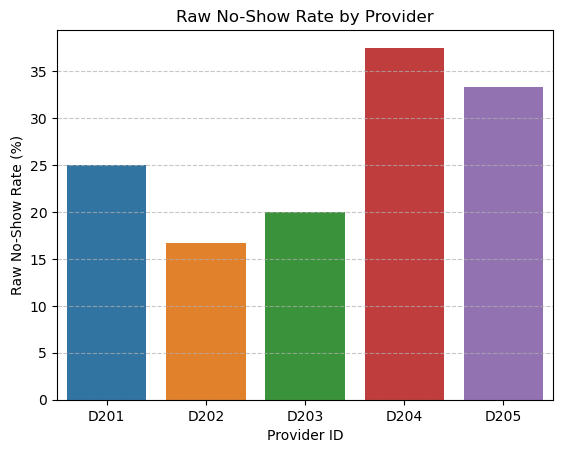

In [1861]:
# Reset the index to make 'provider_id' a column for plotting
provider_counts_plot = provider_counts.reset_index()

plt.figure()
sns.barplot(x='provider_id', y='raw_no_show_rate', data=provider_counts_plot, hue='provider_id', legend=False)
plt.title('Raw No-Show Rate by Provider')
plt.xlabel('Provider ID')
plt.ylabel('Raw No-Show Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Task 7: Recompute the rates after applying justified validation/exclusion rules. 

Since we don't have any certain clues for the remain issues in issues log, we will only compute the certain valid values and exclude the uncertain before it's comfirmed.

A data-quality issue is first flagged when a record violates a consistency rule. However, not every flagged record must be excluded from the no-show calculation.

For the no-show metric, the analysis includes only records with status Completed or No Show. Records with contradictory information that makes the appointment status unreliable are excluded. Other quality issues are retained and reported separately when they do not affect the metric definition.

In [1862]:
exclusion = pd.DataFrame([
    {'rule':'Invalid appointment datetime', 'exclude?':'Yes', 'reason':'Appointment cannot be reliably identified'},
    {'rule':'Duplicate appointment ID', 'exclude?':'No', 'reason':'Based on observation, there is partial duplicate that only duplicate on appointmnet ID. Moreover, different status, in which one is Cancelled not affecting on no-show rate.'},
    {'rule':'Unknown patient ID', 'exclude?':'No', 'reason':'Provider and outcome remain usable'},
    {'rule':'Unknown provider ID', 'exclude?':'No', 'reason':'The status is Cancelled, which is not affected on no-show rate.'},
    {'rule':'Booking after appointment', 'exclude?':'Yes', 'reason':'It was flag as error'},
    {'rule':'Checkout before check-in', 'exclude?':'Yes', 'reason':'It was flag as error'},
    {'rule':'Completed visit missing timestamp', 'exclude?':'No', 'reason':'Incomplete but not necessarily contradictory'},
    {'rule':'Cancelled visit with check-in', 'exclude?':'No', 'reason':'The status is Cancelled, which is not affected on no-show rate'},
    {'rule':'No Show visit with visit time', 'exclude?':'Yes', 'reason':'Outcome is internally contradictory'}
])

exclusion

,rule,exclude?,reason
0,Invalid appointment datetime,Yes,Appointment cannot be reliably identified
1,Duplicate appointment ID,No,"Based on observation, there is partial duplica..."
2,Unknown patient ID,No,Provider and outcome remain usable
3,Unknown provider ID,No,"The status is Cancelled, which is not affected..."
4,Booking after appointment,Yes,It was flag as error
5,Checkout before check-in,Yes,It was flag as error
6,Completed visit missing timestamp,No,Incomplete but not necessarily contradictory
7,Cancelled visit with check-in,No,"The status is Cancelled, which is not affected..."
8,No Show visit with visit time,Yes,Outcome is internally contradictory


In [1863]:
# Exclusion mask
exclude_mask = (
    appts_validation_flags['invalid_appointment_at'] |
    appts_validation_flags['booking_after_appointment'] |
    appts_validation_flags['invalid_visit_times'] |
    appts_validation_flags['no_show_with_visit_time']
)

appointments_validated = appointments[~exclude_mask].copy()

print(f"Original rows: {len(appointments)}")
print(f"Cleaned rows:  {len(appointments_validated)}")
print(f"Excluded {exclude_mask.sum()} records")
appointments.loc[exclude_mask, 'status_standard'].value_counts()

Original rows: 40
Cleaned rows:  35
Excluded 5 records


status_standard
Completed    3
No Show      2
Name: count, dtype: Int64

In [1864]:
# Recompute no-show rate on the validated data 
validated_count = appointments_validated.groupby(
    ["provider_id", "status_standard"]
).size()
validated_eligible = validated_count[
    validated_count.index.get_level_values("status_standard").isin(
        ["Completed", "No Show"]
    )
]

provider_counts_validated = validated_eligible.unstack(fill_value=0)
provider_counts_validated["Eligible"] = (
    provider_counts_validated["Completed"] + provider_counts_validated["No Show"]
)
provider_counts_validated["validated_no_show_rate"] = (
    provider_counts_validated["No Show"] / provider_counts_validated["Eligible"]
) * 100

provider_counts_validated

status_standard,Completed,No Show,Eligible,validated_no_show_rate
provider_id,,,,
D201,6,1,7,14.285714
D202,5,1,6,16.666667
D203,3,1,4,25.000000
D204,4,3,7,42.857143
D205,5,2,7,28.571429


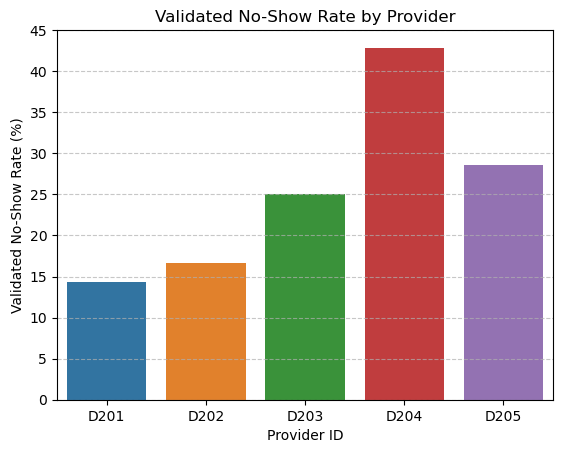

In [1865]:
# Reset the index to make 'provider_id' a column for plotting
provider_counts_validated_plot = provider_counts_validated.reset_index()

plt.figure()
sns.barplot(x='provider_id', y='validated_no_show_rate', data=provider_counts_validated_plot, hue='provider_id', legend=False)
plt.title('Validated No-Show Rate by Provider')
plt.xlabel('Provider ID')
plt.ylabel('Validated No-Show Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

D204 remains highest, while D201 drops substantially after invalid records are removed. This demonstrates why validation can materially change provider comparisons.

## Task 8: Compare the before-cleaning and after-validation rankings of providers. 

In [1866]:
comparison = provider_counts[['raw_no_show_rate']].join(
    provider_counts_validated[['validated_no_show_rate']], how='outer'
)
comparison['raw_rank'] = comparison['raw_no_show_rate'].rank(ascending=False)
comparison['validated_rank'] = comparison['validated_no_show_rate'].rank(ascending=False)
comparison['rank_change'] = comparison['raw_rank'] - comparison['validated_rank']
comparison.sort_values('validated_rank')

status_standard,raw_no_show_rate,validated_no_show_rate,raw_rank,validated_rank,rank_change
provider_id,,,,,
D204,37.500000,42.857143,1.0,1.0,0.0
D205,33.333333,28.571429,2.0,2.0,0.0
D203,20.000000,25.000000,4.0,3.0,1.0
D202,16.666667,16.666667,5.0,4.0,1.0
D201,25.000000,14.285714,3.0,5.0,-2.0


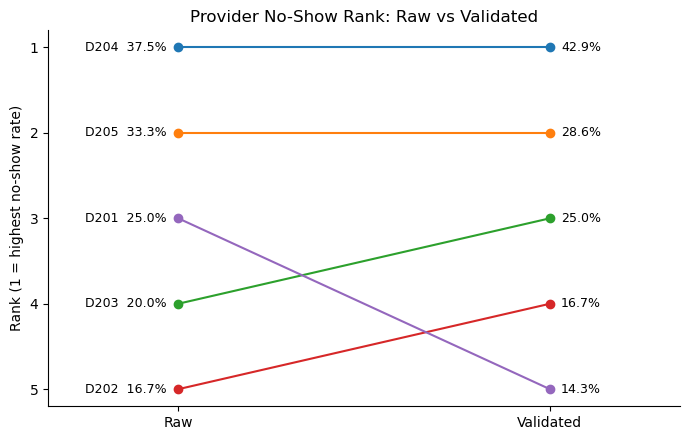

In [1867]:
plot_df = comparison.reset_index().sort_values('validated_rank')
fig, ax = plt.subplots(figsize=(7, 4.5))

for _, row in plot_df.iterrows():
    ax.plot([0, 1], [row['raw_rank'], row['validated_rank']], marker='o', linewidth=1.5)
    ax.text(-0.03, row['raw_rank'], f"{row['provider_id']}  {row['raw_no_show_rate']:.1f}%", ha='right', va='center', fontsize=9)
    ax.text(1.03, row['validated_rank'], f"{row['validated_no_show_rate']:.1f}%", ha='left', va='center', fontsize=9)

ax.set_xlim(-0.35, 1.35)
ax.set_xticks([0, 1], ['Raw', 'Validated'])
ax.set_ylabel('Rank (1 = highest no-show rate)')
ax.invert_yaxis()
ax.set_yticks(range(1, len(plot_df) + 1))
ax.set_title('Provider No-Show Rank: Raw vs Validated')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

After applying the validation rules, the provider rankings changed for some providers.

D204 remained Rank 1, with the highest validated no-show rate.
D205 remained Rank 2.
D203 improved from Rank 4 to Rank 3.
D202 improved from Rank 5 to Rank 4.
D201 decreased from Rank 3 to Rank 5.

The largest change was for D201, whose ranking dropped by two positions after validation. Overall, the validation process affected the provider rankings, demonstrating that data-quality issues can influence comparisons of no-show performance.

## Task 9: Identify whether any provider appears “better” or “worse” mainly because of data-quality problems. 

In [1868]:
comparison[comparison['rank_change'].abs() >= 1]

status_standard,raw_no_show_rate,validated_no_show_rate,raw_rank,validated_rank,rank_change
provider_id,,,,,
D201,25.000000,14.285714,3.0,5.0,-2.0
D202,16.666667,16.666667,5.0,4.0,1.0
D203,20.000000,25.000000,4.0,3.0,1.0


The validated results show that D204 had the highest no-show rate, followed by D205. These two providers remained the top two providers before and after validation. The remaining providers experienced ranking changes after records with identified data-quality issues were excluded from the validated analysis. In particular, D201 moved from 3rd to 5th, while D203 moved from 4th to 3rd and D202 moved from 5th to 4th. This comparison shows why the validated results are more appropriate for provider-level performance comparisons, while the raw results provide a useful baseline for understanding how data-quality issues affected the analysis.

## Task 10: Would you evaluate provider performance using the raw report?

No. Provider performance should not be evaluated solely from the raw report because the raw data contain inconsistent status labels, invalid and contradictory timestamps, unmatched identifiers, duplicate appointment IDs, and other quality issues. A performance report should use the validated no-show definition and denominator, while retaining an issue log so unresolved records can be investigated rather than silently discarded.

Although the no-show rate is calculated using only Completed and No Show appointments, Cancelled appointments should continue to be excluded from the no-show denominator but monitored separately. In particular, records with unresolved patient or provider identifiers should be corrected at the source before using them for subgroup or provider-level reporting when their analytical role is material. The analysis should therefore focus on the Completed and No Show appointments when evaluating provider no-show performance, while cancelled appointments should remain available for separate data-quality and operational analysis.